# Solution: Mini-Project 3 — Weather Analysis

**Dataset:** `weather_data.csv` (daily weather for Hyderabad, Chennai, Delhi and Mumbai, 2023–2024)
**Objective:** explore weather patterns and trends across cities and seasons.

**Deliverable:** this notebook, completed. Each task needs code, its output and a short markdown explanation.
It must run top to bottom. Finish with an *Insights* section.

**Definitions used in this project**
- Seasons in India: **Winter** Dec–Feb, **Summer** Mar–May, **Monsoon** Jun–Sep, **Post-monsoon** Oct–Nov
- A **rainy day** has 2.5 mm of rainfall or more (the definition used by the India Meteorological Department)
- `-99` is an error code the sensor records when it fails. It is **not** a real reading.

**Student name:** _____________ &nbsp;&nbsp; **Roll no.:** _____________ &nbsp;&nbsp; **Section:** ___

> **Instructor solution.** Attempt the exercises yourself before reading this. Your answers may differ in method and still be correct.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_DIR = "../../datasets/"
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (11, 4.5)
pd.set_option("display.float_format", "{:,.2f}".format)

MEASURES = ["Max_Temp_C", "Min_Temp_C", "Humidity_Pct", "Rainfall_mm", "Wind_Speed_kmh"]
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
SEASONS = ["Winter", "Summer", "Monsoon", "Post-monsoon"]

## A. Data preparation

### Exercise 1 — Load and inspect

Load the data with `Date` parsed as a date. Check the date range, the rows per city, duplicates, missing values and any impossible readings.

In [2]:
raw = pd.read_csv(DATA_DIR + "weather_data.csv", parse_dates=["Date"])
print("Shape:", raw.shape, "| from", raw["Date"].min().date(), "to", raw["Date"].max().date())
print(raw["City"].value_counts().to_string(), end="\n\n")
print("Duplicate rows:", raw.duplicated().sum())
print("Duplicate (City, Date) pairs:", raw.duplicated(["City", "Date"]).sum())
print("\nMissing values:\n", raw.isna().sum())
print("\n-99 error codes:\n", (raw[MEASURES] == -99).sum())

Shape: (2934, 7) | from 2023-01-01 to 2024-12-31
City
Chennai      735
Mumbai       734
Delhi        733
Hyderabad    732

Duplicate rows: 10
Duplicate (City, Date) pairs: 10

Missing values:
 Date               0
City               0
Max_Temp_C        69
Min_Temp_C        65
Humidity_Pct      90
Rainfall_mm       45
Wind_Speed_kmh    30
dtype: int64

-99 error codes:
 Max_Temp_C        8
Min_Temp_C        0
Humidity_Pct      5
Rainfall_mm       0
Wind_Speed_kmh    0
dtype: int64


> **Note:** 2023 has 365 days and 2024 has 366, so 731 days × 4 cities = 2,924 rows are expected. The 10 extra rows are duplicates.

### Exercise 2 — Handle errors and missing values

1. Remove duplicates.
2. Replace `-99` with `NaN`.
3. Show missing values per city as a table.
4. Fill gaps in temperature, humidity and wind speed by **time interpolation within each city** (at most 3 days in a row).
5. Decide what to do with missing rainfall and justify your choice.
6. Check that `Min_Temp_C` is never above `Max_Temp_C`.

In [3]:
df = raw.drop_duplicates().sort_values(["City", "Date"]).reset_index(drop=True)
df[MEASURES] = df[MEASURES].replace(-99.0, np.nan)

display(df.groupby("City")[MEASURES].apply(lambda g: g.isna().sum()))

for col in ["Max_Temp_C", "Min_Temp_C", "Humidity_Pct", "Wind_Speed_kmh"]:
    df[col] = df.groupby("City")[col].transform(lambda s: s.interpolate(limit=3, limit_direction="both"))

rain_missing = df["Rainfall_mm"].isna().sum()
df["Rainfall_Missing"] = df["Rainfall_mm"].isna()
df["Rainfall_mm"] = df["Rainfall_mm"].fillna(0.0)
print(f"Rainfall: {rain_missing} missing days filled with 0 and flagged in 'Rainfall_Missing'")

print("Remaining missing:", df[MEASURES].isna().sum().sum())
print("Rows with Min > Max:", (df["Min_Temp_C"] > df["Max_Temp_C"]).sum())

,Max_Temp_C,Min_Temp_C,Humidity_Pct,Rainfall_mm,Wind_Speed_kmh
City,,,,,
Chennai,25,15,27,8,8
Delhi,17,22,24,9,6
Hyderabad,19,15,19,13,5
Mumbai,16,13,25,15,11


Rainfall: 45 missing days filled with 0 and flagged in 'Rainfall_Missing'
Remaining missing: 0
Rows with Min > Max: 0


> **Note:** Temperature, humidity and wind change smoothly from day to day, so interpolating between the neighbouring days is a good estimate. Rainfall does **not** change smoothly. Interpolating would invent rain on dry days. Most days are dry, so a missing reading is filled with 0 and **flagged**. Totals may therefore slightly understate the true rainfall.

### Exercise 3 — Feature engineering

Add `Year`, `Month` (number), `Month_Name`, `Season` (using the Indian seasons above), `Temp_Range` (max − min) and `Rainy_Day` (True when rainfall ≥ 2.5 mm).

In [4]:
season_map = {12: "Winter", 1: "Winter", 2: "Winter", 3: "Summer", 4: "Summer", 5: "Summer",
              6: "Monsoon", 7: "Monsoon", 8: "Monsoon", 9: "Monsoon", 10: "Post-monsoon", 11: "Post-monsoon"}
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Month_Name"] = pd.Categorical(df["Date"].dt.strftime("%b"), categories=MONTHS, ordered=True)
df["Season"] = pd.Categorical(df["Month"].map(season_map), categories=SEASONS, ordered=True)
df["Temp_Range"] = df["Max_Temp_C"] - df["Min_Temp_C"]
df["Rainy_Day"] = df["Rainfall_mm"] >= 2.5
df.head()

,Date,City,Max_Temp_C,Min_Temp_C,Humidity_Pct,Rainfall_mm,Wind_Speed_kmh,Rainfall_Missing,Year,Month,Month_Name,Season,Temp_Range,Rainy_Day
0,2023-01-01,Chennai,28.30,21.70,77.00,0.00,14.60,False,2023,1,Jan,Winter,6.60,False
1,2023-01-02,Chennai,33.00,25.30,71.00,0.00,8.10,False,2023,1,Jan,Winter,7.70,False
2,2023-01-03,Chennai,31.00,23.50,79.00,0.00,11.20,False,2023,1,Jan,Winter,7.50,False
3,2023-01-04,Chennai,30.60,23.70,77.00,0.00,14.20,False,2023,1,Jan,Winter,6.90,False
4,2023-01-05,Chennai,29.40,22.40,83.00,0.00,16.80,False,2023,1,Jan,Winter,7.00,False


## B. Temperature trends

### Exercise 4 — Monthly temperature profile

Plot the average monthly maximum temperature for each city (one line per city, using both years). Which city has the largest gap between its hottest and coolest month, and which has the smallest?

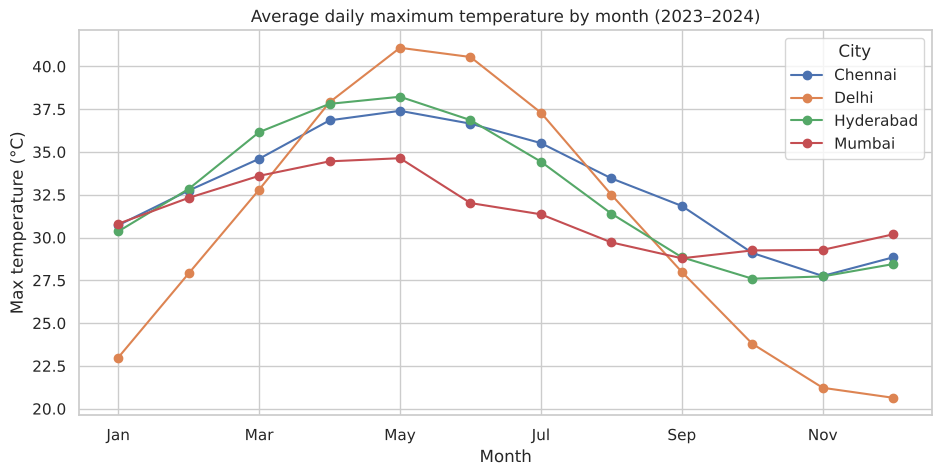

Gap between hottest and coolest month (°C):
 City
Delhi       20.40
Hyderabad   10.60
Chennai      9.60
Mumbai       5.80
dtype: float64
Hottest month per city: {'Chennai': 'May', 'Delhi': 'May', 'Hyderabad': 'May', 'Mumbai': 'May'}


In [5]:
mt = df.pivot_table(index="Month_Name", columns="City", values="Max_Temp_C", aggfunc="mean", observed=True)
ax = mt.plot(marker="o", figsize=(11, 5))
ax.set(title="Average daily maximum temperature by month (2023–2024)", xlabel="Month", ylabel="Max temperature (°C)")
ax.legend(title="City")
plt.show()

swing = (mt.max() - mt.min()).sort_values(ascending=False)
print("Gap between hottest and coolest month (°C):\n", swing.round(1))
print("Hottest month per city:", mt.idxmax().astype(str).to_dict())

> **Note:** Delhi, far inland and in the north, has the largest seasonal swing: hot summers and cool winters. Mumbai and Chennai are on the coast, where the sea keeps temperatures steady through the year.

### Exercise 5 — Smoothing a noisy series

For **Delhi**, plot the daily max temperature over both years together with its 30-day rolling average. Find the hottest and coldest days (by max and min temperature) for every city.

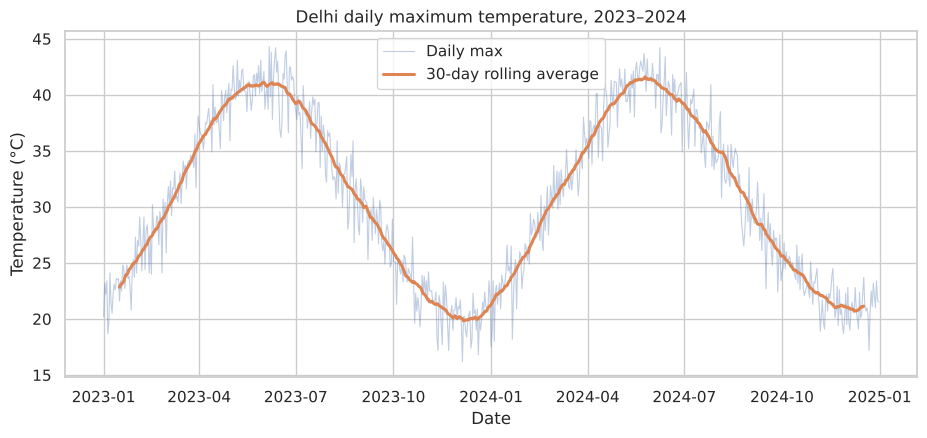

,City,Date_hottest,Max_Temp_C,Date_coldest,Min_Temp_C
0,Chennai,2023-06-05,40.70,2024-11-16,16.50
1,Delhi,2023-06-06,44.30,2023-12-13,3.60
2,Hyderabad,2024-06-10,41.60,2024-10-12,11.30
3,Mumbai,2023-05-16,39.00,2024-09-29,17.60


In [6]:
delhi = df[df["City"] == "Delhi"].set_index("Date")
fig, ax = plt.subplots()
ax.plot(delhi.index, delhi["Max_Temp_C"], alpha=0.35, linewidth=0.8, label="Daily max")
ax.plot(delhi.index, delhi["Max_Temp_C"].rolling(30, center=True).mean(), linewidth=2.2, label="30-day rolling average")
ax.set(title="Delhi daily maximum temperature, 2023–2024", xlabel="Date", ylabel="Temperature (°C)")
ax.legend()
plt.show()

hot = df.loc[df.groupby("City")["Max_Temp_C"].idxmax(), ["City", "Date", "Max_Temp_C"]]
cold = df.loc[df.groupby("City")["Min_Temp_C"].idxmin(), ["City", "Date", "Min_Temp_C"]]
display(hot.merge(cold, on="City", suffixes=("_hottest", "_coldest")))

### Exercise 6 — Year-on-year comparison

Compare 2023 and 2024 for each city: average max temperature, total rainfall and number of rainy days. Was 2024 warmer or wetter? (Be careful: is a difference this small meaningful?)

In [7]:
yoy = df.groupby(["City", "Year"]).agg(Avg_Max_Temp=("Max_Temp_C", "mean"),
                                       Total_Rain_mm=("Rainfall_mm", "sum"),
                                       Rainy_Days=("Rainy_Day", "sum")).unstack("Year")
display(yoy.round(1))

Avg_Max_Temp       Total_Rain_mm          Rainy_Days     
Year              2023  2024          2023     2024       2023 2024
City                                                               
Chennai          33.00 32.90      1,641.70 2,129.40         89   91
Delhi            30.40 30.70      1,007.80   974.10         56   59
Hyderabad        32.50 32.60      1,181.90 1,086.40         71   77
Mumbai           31.50 31.30      2,947.70 2,612.80        101   87

> **Note:** Two years of data are not enough to call a difference of a few tenths of a degree a 'trend'. Natural year-to-year variation is larger than that. Climate trends need decades of data.

## C. Seasonal analysis

### Exercise 7 — Season × city summary

For each city and season, compute: average max temperature, average humidity, total rainfall (average per year) and the percentage of rainy days. Show max temperature by season and city as a box plot.

Avg_Max_Temp  Avg_Humidity  Rain_per_Year_mm  \
City      Season                                                       
Chennai   Winter               30.70         79.50            278.80   
          Summer               36.30         74.00             30.60   
          Monsoon              34.40         83.60            392.30   
          Post-monsoon         28.40         94.10          1,183.90   
Delhi     Winter               23.70         52.80             45.40   
          Summer               37.30         52.40             22.60   
          Monsoon              34.60         66.40            906.40   
          Post-monsoon         22.50         50.80             16.50   
Hyderabad Winter               30.50         55.90             18.40   
          Summer               37.40         58.50             49.80   
          Monsoon              32.90         74.90            969.40   
          Post-monsoon         27.70         61.30             96.60   
Mumbai    Winter               31.10         70.60              3.20   
          Summer               34.20         70.90             17.40   
          Monsoon              30.50         95.00          2,701.70   
          Post-monsoon         29.30         74.20             58.00   

                        Rainy_Day_Pct  
City      Season                       
Chennai   Winter                17.10  
          Summer                 4.30  
          Monsoon               24.20  
          Post-monsoon          67.20  
Delhi     Winter                 6.10  
          Summer                 3.80  
          Monsoon               38.50  
          Post-monsoon           2.50  
Hyderabad Winter                 3.30  
          Summer                 7.10  
          Monsoon               45.90  
          Post-monsoon          13.90  
Mumbai    Winter                 0.60  
          Summer                 2.20  
          Monsoon               69.70  
          Post-monsoon          10.70

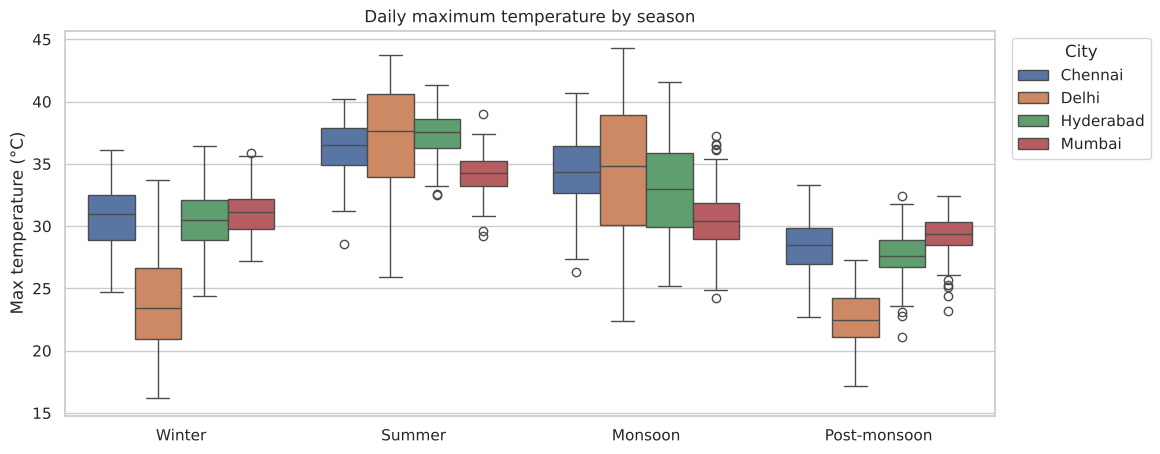

In [8]:
n_years = df["Year"].nunique()
seasonal = df.groupby(["City", "Season"], observed=True).agg(
    Avg_Max_Temp=("Max_Temp_C", "mean"),
    Avg_Humidity=("Humidity_Pct", "mean"),
    Rain_per_Year_mm=("Rainfall_mm", lambda s: s.sum() / n_years),
    Rainy_Day_Pct=("Rainy_Day", lambda s: s.mean() * 100))
display(seasonal.round(1))

fig, ax = plt.subplots(figsize=(12, 5))
sns.boxplot(data=df, x="Season", y="Max_Temp_C", hue="City", order=SEASONS, ax=ax)
ax.set(title="Daily maximum temperature by season", xlabel="", ylabel="Max temperature (°C)")
ax.legend(title="City", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.show()

### Exercise 8 — Which season is wettest where?

For each city, what share (%) of its annual rainfall falls in each season? Show it as a 100% stacked bar chart. Which city does **not** follow the usual 'monsoon = June–September' pattern, and why?

Season,Winter,Summer,Monsoon,Post-monsoon
City,,,,
Chennai,14.80,1.60,20.80,62.80
Delhi,4.60,2.30,91.50,1.70
Hyderabad,1.60,4.40,85.50,8.50
Mumbai,0.10,0.60,97.20,2.10


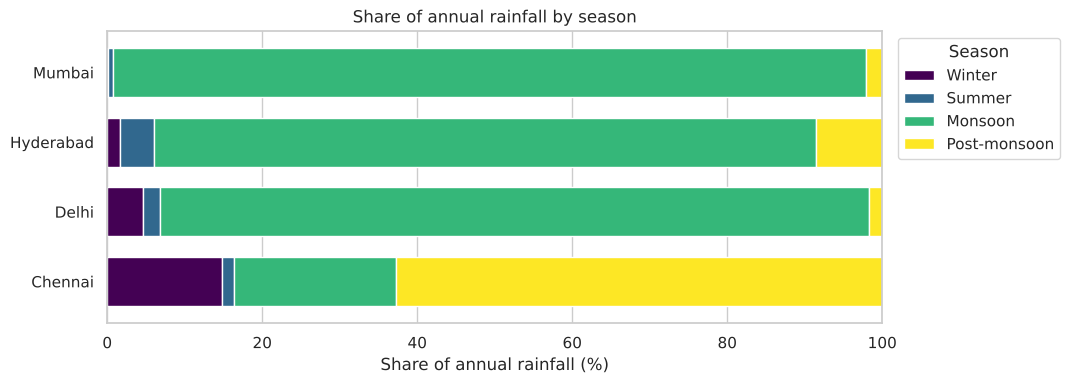

In [9]:
share = df.pivot_table(index="City", columns="Season", values="Rainfall_mm", aggfunc="sum", observed=True)
share = share.div(share.sum(axis=1), axis=0) * 100
display(share.round(1))

ax = share.plot(kind="barh", stacked=True, figsize=(10, 3.8), colormap="viridis", width=0.7)
ax.set(title="Share of annual rainfall by season", xlabel="Share of annual rainfall (%)", ylabel="", xlim=(0, 100))
ax.legend(title="Season", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.show()

> **Note:** **Chennai** gets most of its rain in the **post-monsoon** months (October–November) from the north-east monsoon. The south-west monsoon, which soaks Mumbai, Hyderabad and Delhi from June to September, brings Chennai much less, because Chennai lies in the rain shadow of the Western Ghats.

## D. Rainfall visualisation

### Exercise 9 — Monthly rainfall

Create (a) a grid of four bar charts, one per city, showing average monthly rainfall, using `sns.catplot` or subplots, and (b) a heatmap of average monthly rainfall (city × month). Which city-month is the wettest?

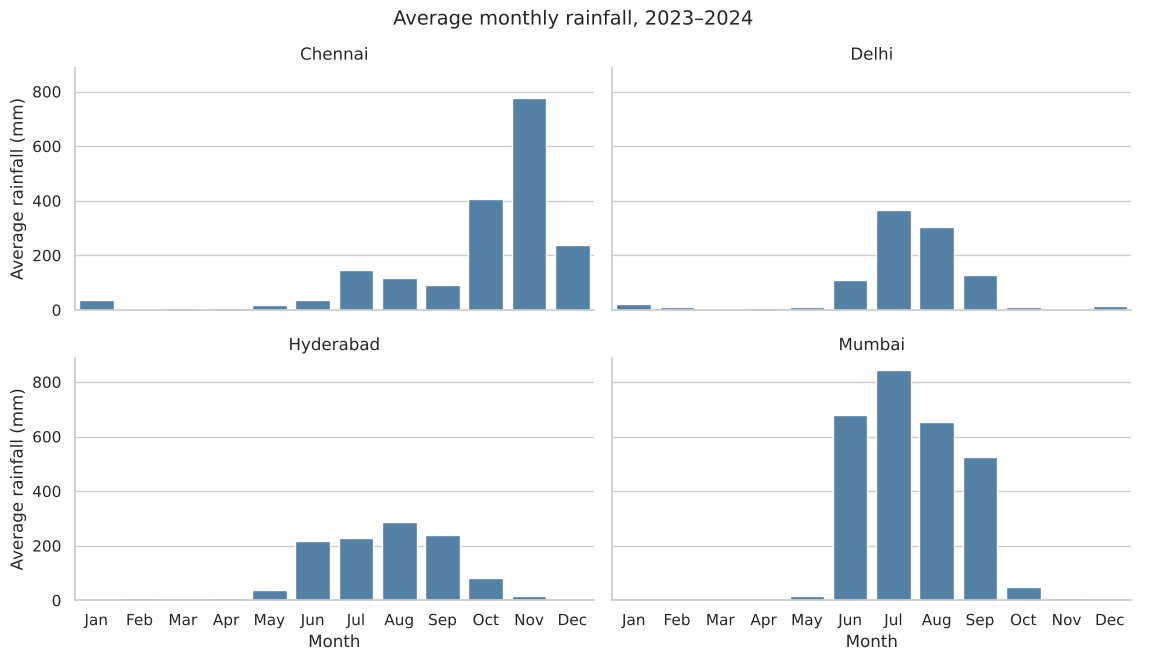

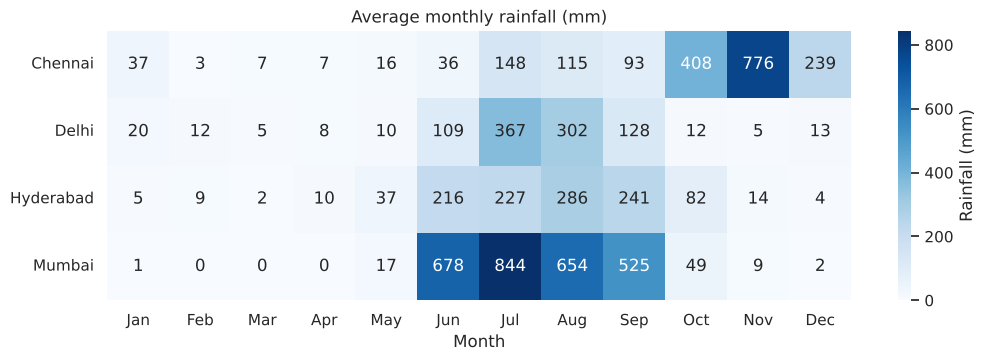

Wettest city-month: Mumbai in Jul (844 mm on average)


In [10]:
monthly_rain = (df.groupby(["City", "Year", "Month_Name"], observed=True)["Rainfall_mm"].sum()
                .groupby(["City", "Month_Name"], observed=True).mean().reset_index())

g = sns.catplot(data=monthly_rain, x="Month_Name", y="Rainfall_mm", col="City", col_wrap=2,
                kind="bar", height=3.2, aspect=1.8, color="steelblue")
g.set_axis_labels("Month", "Average rainfall (mm)")
g.set_titles("{col_name}")
g.fig.suptitle("Average monthly rainfall, 2023–2024", y=1.03, fontsize=14)
plt.show()

heat = monthly_rain.pivot(index="City", columns="Month_Name", values="Rainfall_mm")
fig, ax = plt.subplots(figsize=(12, 3.5))
sns.heatmap(heat, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "Rainfall (mm)"}, ax=ax)
ax.set(title="Average monthly rainfall (mm)", xlabel="Month", ylabel="")
plt.show()

wettest = heat.stack().idxmax()
print(f"Wettest city-month: {wettest[0]} in {wettest[1]} ({heat.stack().max():.0f} mm on average)")

### Exercise 10 — Rain, humidity and temperature

Does rain make days cooler and more humid? Compare average max temperature and humidity on rainy vs dry days for each city during the **monsoon** season only, and show it as a grouped bar chart.

,Max_Temp_C (dry),Max_Temp_C (rainy),Humidity_Pct (dry),Humidity_Pct (rainy)
City,,,,
Chennai,35.00,32.30,81.50,90.00
Delhi,35.30,33.40,63.30,71.30
Hyderabad,34.10,31.40,71.20,79.20
Mumbai,32.20,29.70,91.20,96.70


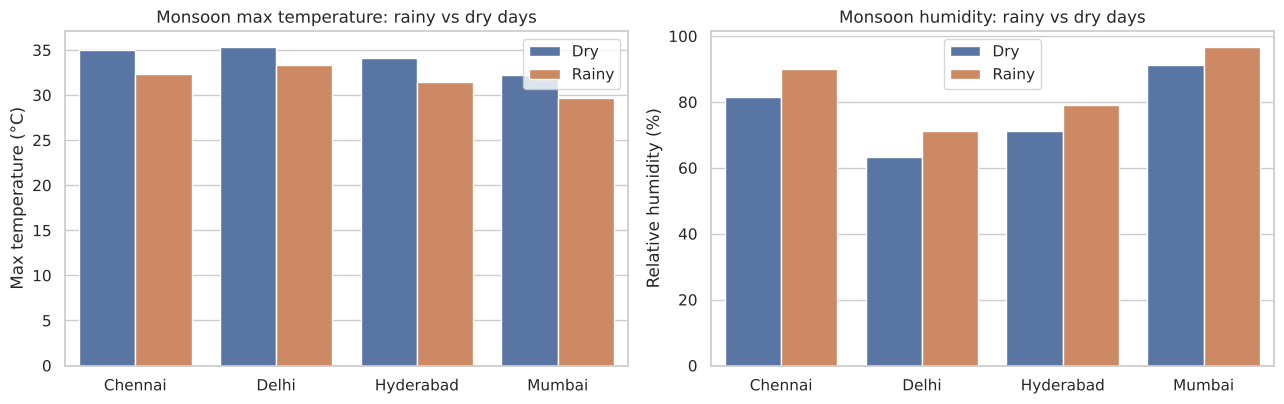

In [11]:
mon = df[df["Season"] == "Monsoon"]
comp = mon.groupby(["City", "Rainy_Day"])[["Max_Temp_C", "Humidity_Pct"]].mean().unstack("Rainy_Day")
comp.columns = [f"{m} ({'rainy' if r else 'dry'})" for m, r in comp.columns]
display(comp.round(1))

plot_df = mon.assign(Day_Type=np.where(mon["Rainy_Day"], "Rainy", "Dry"))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
sns.barplot(data=plot_df, x="City", y="Max_Temp_C", hue="Day_Type", errorbar=None, ax=axes[0])
axes[0].set(title="Monsoon max temperature: rainy vs dry days", xlabel="", ylabel="Max temperature (°C)")
sns.barplot(data=plot_df, x="City", y="Humidity_Pct", hue="Day_Type", errorbar=None, ax=axes[1])
axes[1].set(title="Monsoon humidity: rainy vs dry days", xlabel="", ylabel="Relative humidity (%)")
for ax in axes:
    ax.legend(title="")
plt.tight_layout()
plt.show()

## E. Insights

### Exercise 11 — Insights

Write **at least five insights** about temperature, seasons and rainfall, each backed by a number, and one practical use of these findings (for example in agriculture, events, or water planning). Mention the data's limitations.

In [12]:
annual_rain = df.groupby("City")["Rainfall_mm"].sum() / n_years
print("Average annual rainfall (mm):\n", annual_rain.round(0).sort_values(ascending=False))
print("\nLargest seasonal temperature swing:", swing.idxmax(), f"({swing.max():.1f} °C)")
print("Chennai post-monsoon share of rain:", f"{share.loc['Chennai', 'Post-monsoon']:.0f}%")

Average annual rainfall (mm):
 City
Mumbai      2,780.00
Chennai     1,886.00
Hyderabad   1,134.00
Delhi         991.00
Name: Rainfall_mm, dtype: float64

Largest seasonal temperature swing: Delhi (20.4 °C)
Chennai post-monsoon share of rain: 63%


> **Note:** **Sample insights** (check the exact figures against your own output)
1. Mumbai is by far the wettest city, and most of its rain falls in June–September.
2. Chennai's rainfall peaks in October–November (north-east monsoon), unlike the other three cities.
3. Delhi has the widest temperature swing between summer (May–June) and winter (Dec–Jan). The coastal cities stay within a narrow range.
4. In every city, temperatures peak in May, before the monsoon, not in July. Monsoon cloud and rain cool the days.
5. In the monsoon, rainy days are cooler and more humid than dry days.

**Practical use:** water-supply and drainage planning in Chennai should prepare for October–November, not June.
Outdoor events in Hyderabad and Delhi are best placed in Nov–Feb.

**Limitations:** two years of synthetic data; missing rainfall was filled with zero; one weather station per city.